Mean: 45006.45
Standard Deviation: 164.30


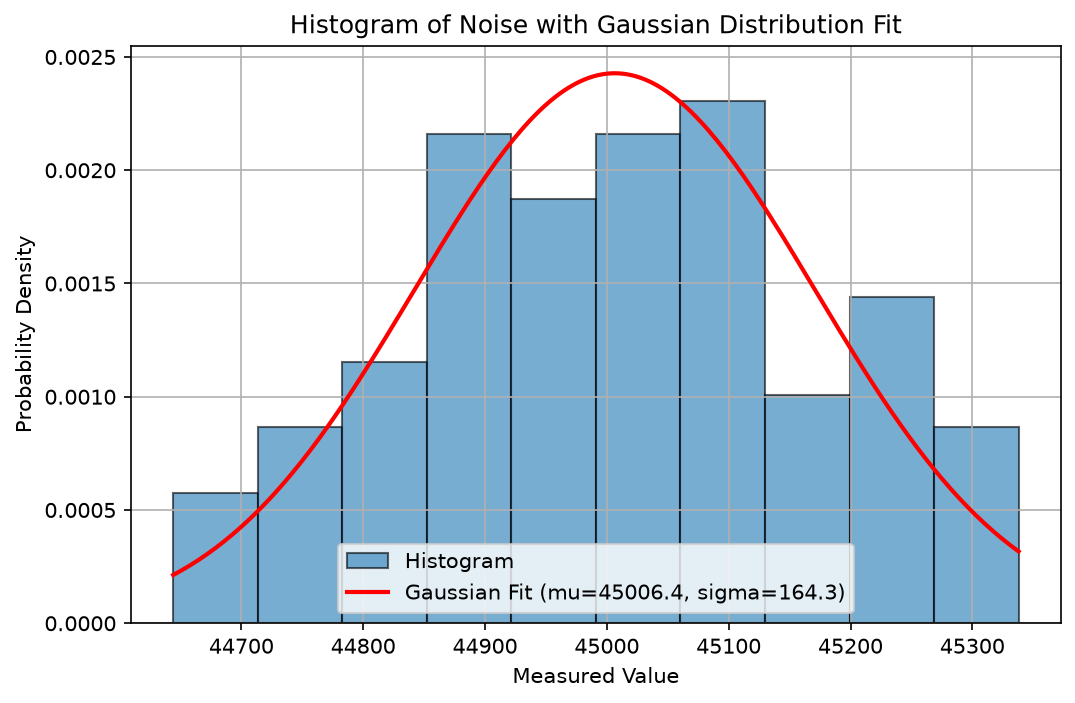

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Load and convert the list to a np.array
with open("noise.csv", "r") as f:
    lines = f.readlines()[1:]  # skip header
    noise_list = [float(line.strip().split(",")[1]) for line in lines if line.strip()]

data = np.array(noise_list)

# 2. Calculate mean and standard deviation (ddof=1 for sample standard deviation)
mean = np.mean(data)
std = np.std(data, ddof=1)

print(f"Mean: {mean:.2f}")
print(f"Standard Deviation: {std:.2f}")

# 3. Plot histogram with an appropriate number of bins
plt.figure(figsize=(8, 5))
count, bins, _ = plt.hist(data, bins=10, density=True, edgecolor="black", alpha=0.6, label="Histogram")

# 4. Fit Gaussian distribution to the values / histogram and show in the same plot
x = np.linspace(min(data), max(data), 200)
gaussian = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)
plt.plot(x, gaussian, "r-", linewidth=2, label=f"Gaussian Fit (mu={mean:.1f}, sigma={std:.1f})")

# 5. Label axes, title, legend, and save graph as a pdf file
plt.xlabel("Measured Value")
plt.ylabel("Probability Density")
plt.title("Histogram of Noise with Gaussian Distribution Fit")
plt.legend()
plt.grid(True)

plt.savefig("statistical_analysis_nachiketh_histogram.pdf", bbox_inches="tight")
plt.show()
